# 02 — The paper's model, with noise injected in Guppy, agrees with Stim

Can the paper's phenomenological findings be reproduced with
artificial noise injected inside a Guppy program, as a device program would run? Within
the model's constraints (bit-flip data noise, readout that flips only the record), yes.

**Source:** `python -m qec_timing.validation.crosscheck` → `results/crosscheck/crosscheck.json`.
Rotated surface code, Z basis, p = 0.015, λ = 1, b_read = 1, T = 10, the original Stage 4a
grid at d = 5, 7, 9. Both backends' records are decoded by the same PyMatching decoder.

In [1]:
import json
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from qec_timing import plotting as P
P.style()
R = Path("..") / "results"

In [2]:
cc = json.loads((R / "crosscheck" / "crosscheck.json").read_text())
s = cc["summary"]
print(f"{s['points_overlapping']}/{s['points']} points: 99.9% intervals overlap")
for k, v in s.items():
    if isinstance(v, dict):
        print(f"{k:<40} chi2 = {v['chi2']:.1f} on {v['n_points']} (p = {v['chi2_p']:.2f}), "
              f"mean offset {v['mean_z_sigma']:+.1f} sigma")

18/18 points: 99.9% intervals overlap
guppy_vs_stim                            chi2 = 17.1 on 18 (p = 0.51), mean offset -1.9 sigma
stim_vs_original_reference               chi2 = 10.3 on 18 (p = 0.92), mean offset -0.8 sigma
original_guppy_vs_original_reference     chi2 = 22.7 on 18 (p = 0.20), mean offset -0.4 sigma


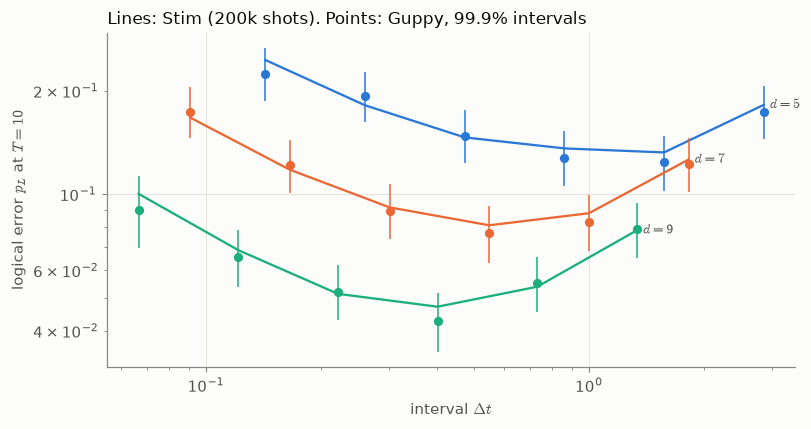

In [3]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for d in (5, 7, 9):
    rows = [r for r in cc["rows"] if r["d"] == d]
    dt = np.array([r["dt"] for r in rows])
    st = np.array([r["stim"]["p_L"] for r in rows])
    g = np.array([r["guppy"]["p_L"] for r in rows])
    glo = g - np.array([r["guppy"]["ci"][0] for r in rows]); ghi = np.array([r["guppy"]["ci"][1] for r in rows]) - g
    c = P.SERIES[(5, 7, 9).index(d)]                       # slots 1-3 for this study's distances
    ax.plot(dt, st, "-", color=c, lw=1.5)
    ax.errorbar(dt, g, yerr=[glo, ghi], fmt="o", color=c, ms=5, capsize=0, lw=1)
    P.label_end(ax, dt[-1], st[-1], P.dl(d))
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"interval $\Delta t$"); ax.set_ylabel(r"logical error $p_L$ at $T = 10$")
ax.set_title("Lines: Stim (200k shots). Points: Guppy, 99.9% intervals", loc="left")
fig.tight_layout()
P.save(fig, "02_paper_model_guppy_vs_stim_1")

**Reading.**
- *Measured:* all 18 points agree within 99.9% intervals; jointly, χ² = 17.1 on 18 (p = 0.51),
  and the mean Guppy–Stim offset is −1.9σ, below any threshold for a real bias. The new Stim
  numbers also reproduce the original repo's reference (p = 0.92).
- *Measured:* each distance shows the U-shape: too-frequent extraction pays p_stab every
  round, too-rare extraction lets idle errors pile up.
- *Method note:* a first run gave Guppy points at the same distance overlapping per-shot seed
  ranges, which correlated them and faked a d = 7 bias; the package now refuses overlapping
  ranges (`spec.overlapping_seed_ranges`). See `results/crosscheck/README.md`.
- *Constraint:* this model has X-only data noise and ideal gates. It
  validates the injection mechanism and the analysis, not device physics; notebooks 04–09 add
  realistic noise.

## The paper's scaling: 1/Δt* grows linearly with d

**Source:** `python -m qec_timing.studies.scaling` → `results/scaling/scaling.json`. Same
model, Stim, 15 intervals per distance from 0.2× to 4× Eq. 6's prediction, 200k shots each;
Δt* from the parabola-in-log fit with a bootstrap interval; 1/Δt* = η d + z by weighted
least squares. The paper's slope 0.402 was fitted on d = 11–27 with T = 200.

In [4]:
sc = json.loads((R / "scaling" / "scaling.json").read_text())
f = sc["fit"]
print(f"1/dt* = ({f['eta']:.3f} +/- {f['eta_se']:.3f}) d + ({f['z']:.3f} +/- {f['z_se']:.3f});  "
      f"paper slope {f['paper_eta']}: {f['sigma_from_paper']:+.1f} sigma")
for r in sc["rows"]:
    o = r["optimum"]
    print(f"d={r['d']:>2}: dt* = {o['dt_star']:.4f} [{o['lo']:.4f}, {o['hi']:.4f}]   Eq. 6 (g = 0.8): {r['eq6']:.4f}")

1/dt* = (0.385 +/- 0.013) d + (-0.920 +/- 0.077);  paper slope 0.402: -1.3 sigma
d= 5: dt* = 0.9878 [0.9803, 0.9961]   Eq. 6 (g = 0.8): 0.7143
d= 7: dt* = 0.5774 [0.5722, 0.5827]   Eq. 6 (g = 0.8): 0.4545
d= 9: dt* = 0.3947 [0.3909, 0.3988]   Eq. 6 (g = 0.8): 0.3333
d=11: dt* = 0.2921 [0.2887, 0.2955]   Eq. 6 (g = 0.8): 0.2632


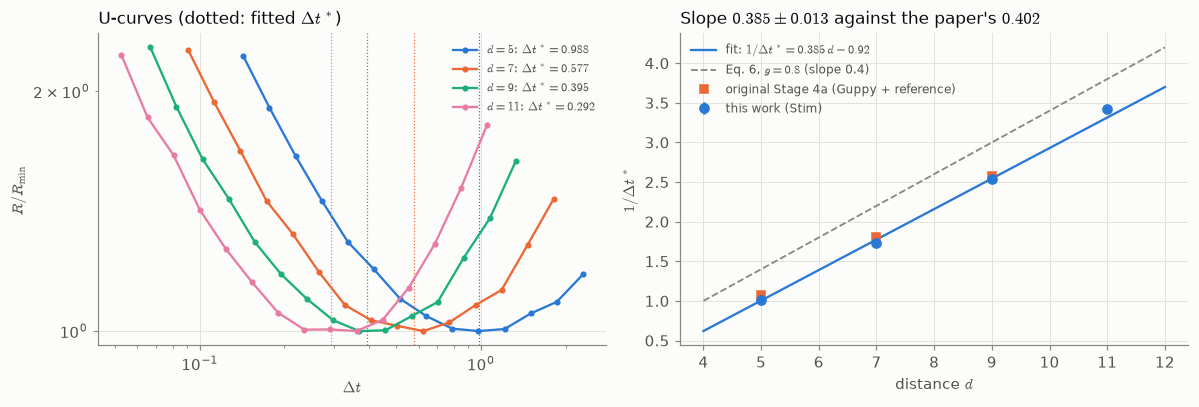

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
cols = dict(zip([r["d"] for r in sc["rows"]], P.SERIES + ["#e87ba4"]))
for r in sc["rows"]:
    pts = r["points"]; c = cols[r["d"]]
    rr = np.array([p["r"] for p in pts]); dt = np.array([p["dt"] for p in pts])
    axes[0].plot(dt, rr / rr.min(), "o-", color=c, ms=3, lw=1.5,
                 label=rf"$d = {r['d']}$: $\Delta t^* = {r['optimum']['dt_star']:.3f}$")
    axes[0].axvline(r["optimum"]["dt_star"], color=c, lw=0.8, ls=":")
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].legend(fontsize=8)
axes[0].set_xlabel(P.DT); axes[0].set_ylabel(r"$R / R_{\min}$")
axes[0].set_title(r"U-curves (dotted: fitted $\Delta t^*$)", loc="left")
d = np.array([r["d"] for r in sc["rows"]], float)
y = np.array([1 / r["optimum"]["dt_star"] for r in sc["rows"]])
s = np.array([(1 / r["optimum"]["lo"] - 1 / r["optimum"]["hi"]) / 2 for r in sc["rows"]])
xs = np.linspace(d.min() - 1, d.max() + 1, 50)
axes[1].errorbar(d, y, yerr=s, fmt="o", color=P.SERIES[0], ms=6, label="this work (Stim)")
axes[1].plot(xs, f["eta"] * xs + f["z"], "-", color=P.SERIES[0], lw=1.5, label=rf"fit: $1/\Delta t^* = {f['eta']:.3f}\,d {f['z']:+.2f}$")
axes[1].plot(xs, 0.8 * (xs + 1) / 2 - 1, "--", color=P.MUTED, lw=1.2,      # Eq. 6: 1/dt* = lam (alpha - 1)
             label=r"Eq. 6, $g = 0.8$ (slope 0.4)")
gx = [5, 7, 9]; gy = [1 / 0.9343, 1 / 0.5546, 1 / 0.3888]
axes[1].plot(gx, gy, "s", color=P.SERIES[1], ms=5, label="original Stage 4a (Guppy + reference)")
axes[1].set_xlabel(r"distance $d$"); axes[1].set_ylabel(r"$1/\Delta t^*$"); axes[1].legend(fontsize=8)
axes[1].set_title(rf"Slope ${f['eta']:.3f} \pm {f['eta_se']:.3f}$ against the paper's $0.402$", loc="left")
fig.tight_layout()
P.save(fig, "02_paper_model_guppy_vs_stim_2")

**Reading.**
- *Measured:* 1/Δt* is linear in d with slope 0.385 ± 0.013, within 1.3σ of the paper's 0.402,
  and twice as precise as the original Stage 4a fit (0.376 ± 0.026).
- *Measured:* the fitted Δt* sits above Eq. 6 by +38% at d = 5, falling to +11% at d = 11. Eq. 6
  uses the paper's g = 0.8, fitted at d = 11–27; at small d the effective g is lower (original
  Stage 4a: g ≈ 0.70), and the gap closes as d grows, as it should.